In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the house prices dataset

df = pd.read_csv("train.csv")

# Display first five rows
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Display statistical summary
df.describe()

Dataset Shape: (1460, 81)

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


House Price Statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


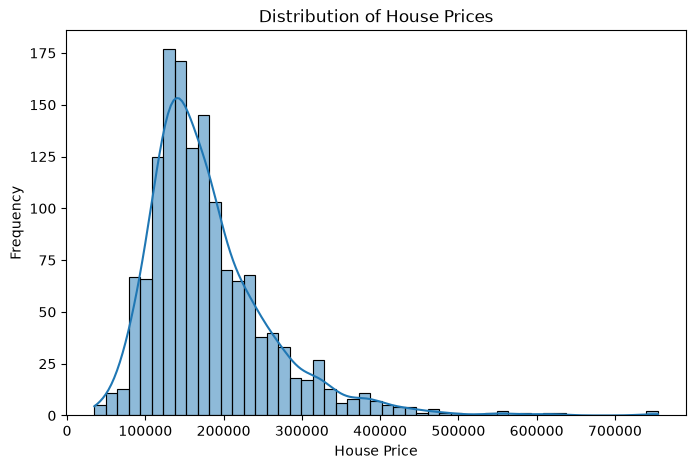

In [4]:
# Descriptive statistics of house prices

print("House Price Statistics:")
print(df['SalePrice'].describe())

# Plot house price distribution

plt.figure(figsize=(8, 5))
sns.histplot(df['SalePrice'], kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()

### Observation – House Price Distribution

- Most houses have prices within the lower to middle range.
- A few houses have very high prices.
- The distribution is right-skewed.
- House prices vary across the dataset.

## Feature Selection

The following features are useful for predicting house prices:

1. OverallQual – Overall material and finish quality.
2. GrLivArea – Above-ground living area.
3. GarageCars – Garage capacity.
4. TotalBsmtSF – Total basement area.
5. YearBuilt – Year the house was built.

These features are selected because house quality, size, garage capacity and age can influence house prices.

In [5]:
# Separate numerical and categorical columns

num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Fill numerical missing values with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [6]:
# Select categorical columns
cat_cols = df.select_dtypes(include=['object']).columns

# Apply One-Hot Encoding
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("Encoding completed successfully!")
print("New Dataset Shape:", df.shape)

Encoding completed successfully!
New Dataset Shape: (1460, 246)


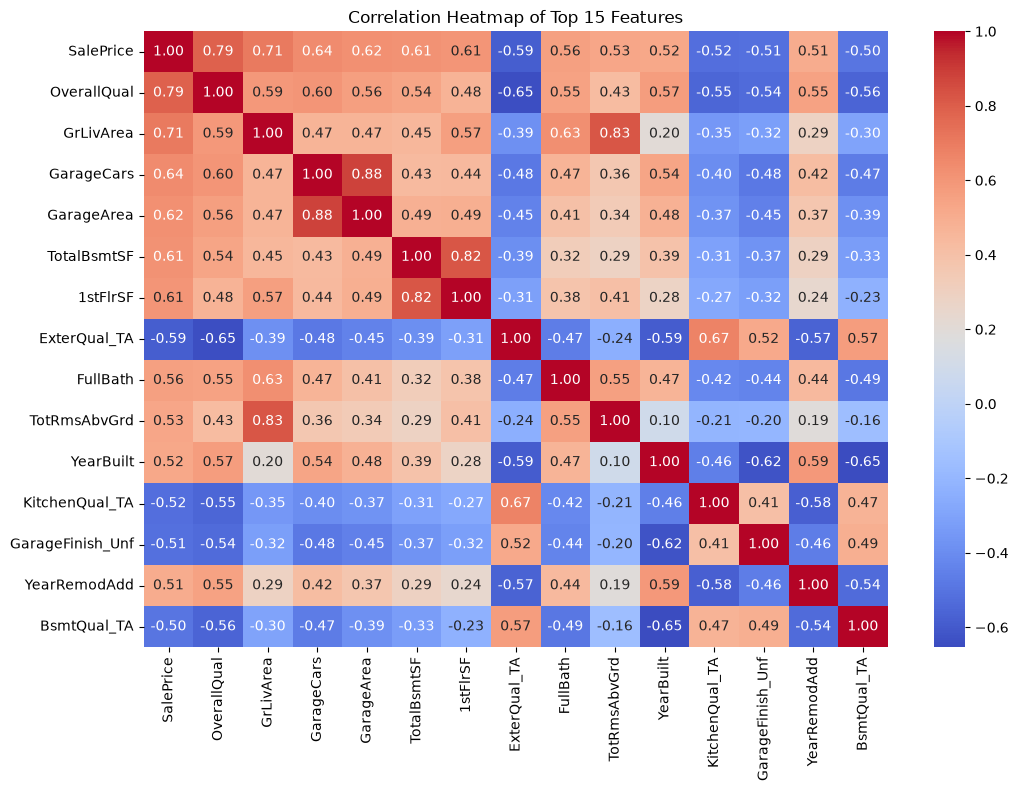

In [7]:
# Calculate correlation with SalePrice

correlation = df.corr(numeric_only=True)['SalePrice']

# Select 15 features with the strongest correlation
top_features = correlation.abs().sort_values(ascending=False).head(15).index

# Create heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Top 15 Features")
plt.show()

In [8]:
# Display features most correlated with house prices

print("Top Features Correlated with SalePrice:")
print(correlation.sort_values(ascending=False).head(10))

Top Features Correlated with SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


In [9]:
# Separate input features and target variable

X = df.drop(['SalePrice', 'Id'], axis=1)
y = df['SalePrice']

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (1168, 244)
Testing data shape: (292, 244)


In [10]:
# Create Linear Regression model

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [11]:
# Predict house prices using test data

y_pred = model.predict(X_test)

print("House Price Predictions:")
print(y_pred[:10])

House Price Predictions:
[156410.27278559 339109.04662501  86638.0223727  187150.80725522
 320799.52503897  64123.0997446  254246.29971874 145528.87657902
  52994.20911772 155774.6326983 ]


In [12]:
# Calculate evaluation metrics

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-----------------------")
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Model Performance
-----------------------
Mean Squared Error (MSE): 1019663649.6546389
Root Mean Squared Error (RMSE): 31932.17264225281
R2 Score: 0.8670638481191048


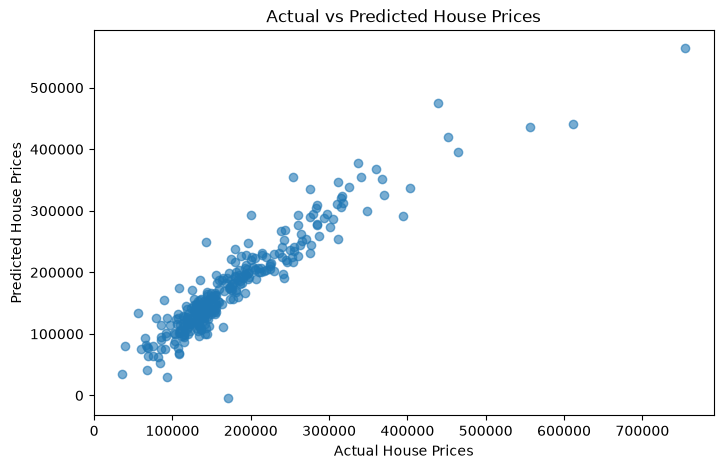

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

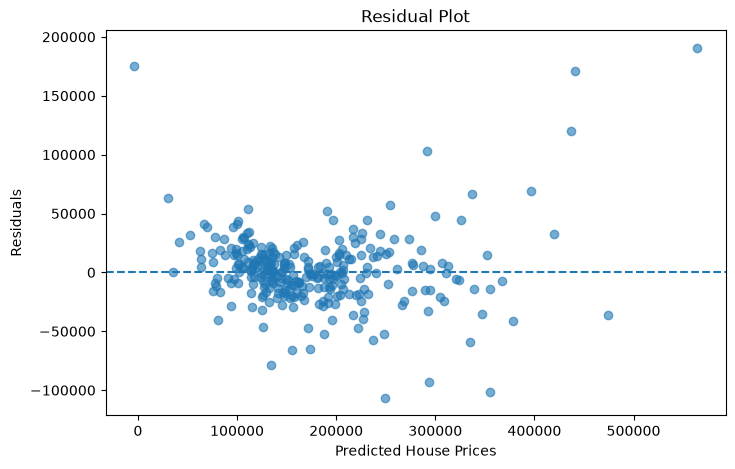

In [14]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [15]:
# Predict house prices using test data

y_pred = model.predict(X_test)

print("House Price Predictions:")
print(y_pred[:10])

House Price Predictions:
[156410.27278559 339109.04662501  86638.0223727  187150.80725522
 320799.52503897  64123.0997446  254246.29971874 145528.87657902
  52994.20911772 155774.6326983 ]


In [16]:
# Calculate evaluation metrics

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-----------------------")
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Model Performance
-----------------------
Mean Squared Error (MSE): 1019663649.6546389
Root Mean Squared Error (RMSE): 31932.17264225281
R2 Score: 0.8670638481191048


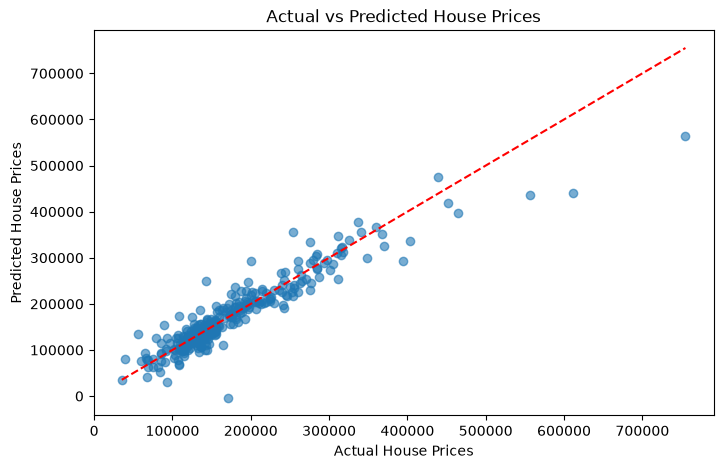

In [17]:
# Actual vs Predicted House Prices

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

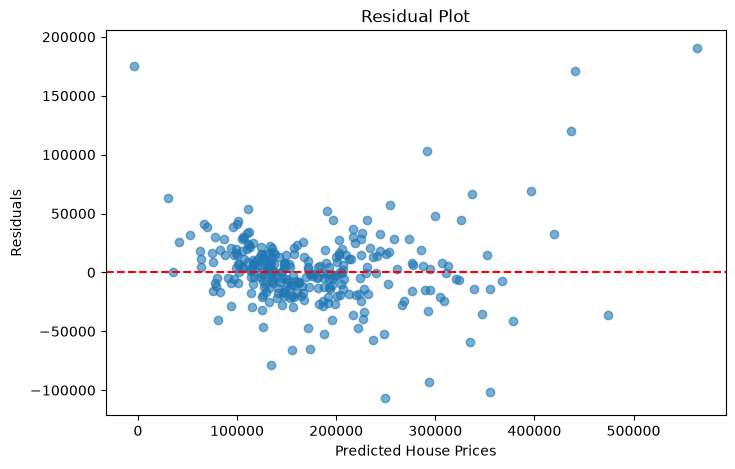

In [18]:
# Calculate residuals

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

## Graph Observations

### Actual vs Predicted Prices
- Most points are close to the red diagonal line.
- The model predicts many house prices reasonably well.
- Some differences are observed between actual and predicted prices.

### Residual Plot
- Most residuals are distributed around the zero line.
- Some large prediction errors and outliers are present.
- Residual variation increases for higher predicted prices.

In [19]:
# Analyze model coefficients

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Value"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Absolute Value", ascending=False
)

print(coefficients.head(10))

              Feature    Coefficient  Absolute Value
224         PoolQC_Gd -287293.506969   287293.506969
90    Condition2_PosN -136483.525244   136483.525244
223         PoolQC_Fa -114832.459376   114832.459376
89    Condition2_PosA  100958.299940   100958.299940
200    Functional_Sev -100109.911701   100109.911701
116  RoofMatl_WdShngl   91714.056165    91714.056165
91    Condition2_RRAe  -79953.556021    79953.556021
105   RoofStyle_Gable  -64787.954622    64787.954622
107     RoofStyle_Hip  -62662.110494    62662.110494
183      Heating_Wall   59697.088582    59697.088582


## Coefficient Analysis

- The model assigns positive and negative coefficients to different features.
- Positive coefficients indicate an increase in predicted house price.
- Negative coefficients indicate a decrease in predicted house price.
- Features such as PoolQC_Gd, Condition2_PosN and Functional_Sev have large coefficient values.
- These coefficients help understand how different features influence model predictions.

## Final Findings and Conclusion

The project uses Linear Regression to predict house prices based on housing features.

### Key Findings

1. The dataset contains 1,460 records and 81 columns.
2. Missing values were handled and categorical features were encoded.
3. A correlation heatmap was used to study relationships between numerical features.
4. The Linear Regression model was trained using an 80:20 train-test split.
5. The model achieved an R² score of 0.8671.
6. Actual vs Predicted and Residual plots were used to evaluate model performance.
7. Coefficient analysis helped understand feature contributions.

### Conclusion

The Linear Regression model explains approximately 86.71% of the variation in house prices. The project demonstrates how machine learning can be used to predict house prices and understand the factors affecting them.